# Embedding diagnostics for CLIP models

This notebook is primarily to assess whether contrastive training shifted the learned representations.

We need to load the `.pt` file saved by `run_inference.py --extract_embeddings` and the
corresponding detection catalog `.json` to help us make plots and investigate the representations.

The .pt file contains:
- emb_q        (N, 128) float32  L2-normalized Rubin embeddings z_q
- emb_k/embeddings_k (N, 128) float32  L2-normalized Roman embeddings z_k  [optional]
- file_name    list[str]          per-detection file name (index-aligned with emb_q)

Super helpful resources:
- https://sites.duke.edu/dimensionreduction/
- https://towardsdatascience.com/why-you-should-not-rely-on-t-sne-umap-or-trimap-f8f5dc333e59/

In [1]:
import argparse
import os

import numpy as np
import pandas as pd
import torch
import matplotlib
print(f"Using matplotlib backend: {matplotlib.get_backend()}")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.manifold import TSNE
from umap import UMAP
from pacmap import PaCMAP
import torch.nn.functional as F

from blend_metrics import get_matched_truth_mag

Using matplotlib backend: module://matplotlib_inline.backend_inline


# Config Setup

In [3]:
MAG_LIMITS = {
    'power_law': 26.22,
    'gold': 25.3,
    'nominal': 26.42,
}
# Choose mode: "auto" (run-based paths) or "explicit" (direct file paths)
mode = "auto"
seed = 42
# Auto mode options
run_name = "clip5_30k_4h200_bs192_ep15"
# run_name = "clip5_30k_4h200_bs64_ep50"
# run_name = "clip5_flatten_30k_4h200_bs64_ep15"
score_thresh = 0.4
nms_thresh = 0.55
data_split = "test"      # eval or test
run_root = "~/lsst_runs"
out_dir = None           # None => defaults to <run_root>/<run_name>/emb_plots
buffer = 1.0
mag_limit = MAG_LIMITS['gold']

# Explicit mode options
emb_pt_explicit = None   # e.g. "/path/to/.../embeddings/emb_s0.4_n0.55.pt"
det_json_explicit = None # e.g. "/path/to/.../pred_s0.4_n0.55.json"
fof_parquet_explicit = None # e.g. "/path/to/.../class_26.30.parquet"
out_dir_explicit = None  # required in explicit mode
pre_nms_embeddings = True # Whether the provided embeddings are pre-NMS (True) or post-NMS (False)

In [4]:
np.random.seed(seed)
if mode not in {"auto", "explicit"}:
    raise ValueError("mode must be 'auto' or 'explicit'.")

if mode == "auto":
    if run_name is None or score_thresh is None or nms_thresh is None:
        raise ValueError("Auto mode requires run_name, score_thresh, and nms_thresh.")
    if data_split not in {"eval", "test"}:
        raise ValueError("data_split must be 'eval' or 'test'.")

    score_tag = str(score_thresh)
    nms_tag = str(nms_thresh)
    run_root_expanded = os.path.expanduser(run_root)
    run_dir = os.path.join(run_root_expanded, run_name)
    pred_dir = os.path.join(run_dir, "preds", data_split)
    fof_parquet = os.path.join(run_dir, f"analysis_cats/dd/1.0/s{score_tag}_n{nms_tag}/class_{mag_limit + buffer:.2f}.parquet")

    if not pre_nms_embeddings:
        emb_pt = os.path.join(pred_dir, "embeddings", f"emb_s{score_tag}_n{nms_tag}.pt")
    else:
        emb_pt = os.path.join(pred_dir, "pre_nms_embeddings", f"proposal_emb_z.pt")
    det_json = os.path.join(pred_dir, f"pred_s{score_tag}_n{nms_tag}.json")
    out_dir = os.path.expanduser(out_dir) if out_dir else os.path.join(run_dir, "emb_plots")
else:  # explicit
    if not emb_pt_explicit or not det_json_explicit:
        raise ValueError("Explicit mode requires emb_pt_explicit and det_json_explicit.")
    if not out_dir_explicit:
        raise ValueError("Explicit mode requires out_dir_explicit.")
    emb_pt = os.path.expanduser(emb_pt_explicit)
    det_json = os.path.expanduser(det_json_explicit)
    fof_parquet = os.path.expanduser(fof_parquet_explicit) if fof_parquet_explicit else None
    out_dir = os.path.expanduser(out_dir_explicit)

missing = [p for p in [emb_pt, det_json, fof_parquet] if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "Resolved input file(s) do not exist:\n" + "\n".join(f"  - {p}" for p in missing)
    )

os.makedirs(out_dir, exist_ok=True)
print("Resolved configuration:")
print(f"  mode:        {mode}")
print(f"  emb_pt:      {emb_pt}")
print(f"  det_json:    {det_json}")
print(f"  fof_parquet: {fof_parquet}")
print(f"  out_dir:     {out_dir}")
print(f"  seed:        {seed}")

Resolved configuration:
  mode:        auto
  emb_pt:      /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/preds/test/pre_nms_embeddings/proposal_emb_z.pt
  det_json:    /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/preds/test/pred_s0.4_n0.55.json
  fof_parquet: /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/analysis_cats/dd/1.0/s0.4_n0.55/class_26.30.parquet
  out_dir:     /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots
  seed:        42


In [5]:
seed=42
np.random.seed(seed)
emb_data = torch.load(emb_pt, map_location='cpu', weights_only=False)
det_df   = pd.read_json(det_json)
fof_df = pd.read_parquet(fof_parquet) if fof_parquet else None
test_df = pd.read_json('/u/yse2/lsst_data/annotations_lvl5/test_8k_keypoints_wcs.json')

In [89]:
emb_data['emb_q'].shape

torch.Size([269903, 128])

# Intra-modal pairwise cosine similarity

In [ ]:
def plot_embedding_distri(emb_data, out_dir=None, n_subsample=2000, savefig=False):
    """
    Plot distribution of pairwise intra-modal cosine similarities for z_q
    All similarities near 1 indicates representation collapse
    """
    z_q = emb_data['emb_q'].float()
    n   = min(len(z_q), n_subsample)
    np.random.seed(seed)
    idx = np.random.choice(len(z_q), n, replace=False)
    z_sub = z_q[idx]

    sim_matrix = (z_sub @ z_sub.T).numpy()
    mask = np.triu(np.ones_like(sim_matrix, dtype=bool), k=1)
    pairwise_sims = sim_matrix[mask]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(pairwise_sims, bins=80, color='steelblue', alpha=0.8)
    ax.axvline(pairwise_sims.mean(), color='red', linestyle='--',
               label=f'mean={pairwise_sims.mean():.3f}')
    ax.set_xlabel('Pairwise cosine similarity (z_q)')
    ax.set_ylabel('Count')
    ax.set_title(f'CLIP: intra-modal pairwise similarity (n={n:,} subsample)')
    ax.legend()
    fig.tight_layout()
    if savefig == True:
        fname = os.path.join(out_dir, 'emb_distrib_clip.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}  (mean={pairwise_sims.mean():.3f}, std={pairwise_sims.std():.3f})")

  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/emb_distrib_clip.png  (mean=0.004, std=0.246)


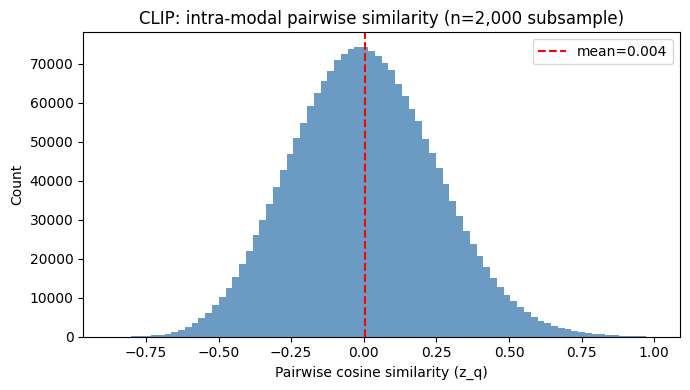

In [41]:
plot_embedding_distri(emb_data, out_dir=out_dir, savefig=True)

The distribution is centered at ~0 and roughly Gaussian, which is exactly what we want. It means the 128-dim z_q embeddings are spread out across the hypersphere and random pairs of dets have near-zero cosine similarity on average. This tells us the embedding space is not collapsed (collapse would look like a spike near 1.0). The model learned a diverse, well-distributed representation space.

# Cross-modal Cosine Similarity 

In [6]:
def plot_cross_modal_cosine_sim(emb_data, det_df, out_dir=None, mag_col='mag_i', savefig=False):
    """
    For each detection compute cos_sim(z_q, z_k) and plot its distribution
    and relationship to magnitude.
    """
    if 'emb_k' not in emb_data and 'embeddings_k' not in emb_data:
        print("  [skip] No Roman embeddings in .pt file.")
        return

    z_q = emb_data['emb_q'].float()
    z_k = emb_data['emb_k'].float() if 'emb_k' in emb_data else emb_data['embeddings_k'].float()
    cos_sim = F.cosine_similarity(z_q, z_k).numpy()

    # distribution
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(cos_sim, bins=80, color='steelblue', alpha=0.8)
    ax.axvline(cos_sim.mean(), color='red', linestyle='--',
               label=f'mean={cos_sim.mean():.3f}')
    ax.set_xlabel('Cosine similarity (z_q · z_k)')
    ax.set_ylabel('Count')
    ax.set_title('Cross-modal cosine similarity distribution (CLIP)')
    ax.legend()
    fig.tight_layout()
    if savefig == True:
        fig.savefig(os.path.join(out_dir, 'cosine_sim_cross_modal.png'), dpi=150)
        print(f"  Saved {os.path.join(out_dir, 'cosine_sim_cross_modal.png')}.png  "
            f"(mean={cos_sim.mean():.3f}, std={cos_sim.std():.3f})")

    # vs magnitude
    if mag_col in det_df.columns:
        mags = det_df[mag_col].values.astype(float)
        valid = np.isfinite(mags) & np.isfinite(cos_sim)
        edges = np.arange(18, 27, 1)
        bin_idx = np.digitize(mags[valid], edges) - 1
        bin_centers = 0.5 * (edges[:-1] + edges[1:])
        bin_means, bin_stds = [], []
        for b in range(len(edges) - 1):
            m = bin_idx == b
            bin_means.append(cos_sim[valid][m].mean() if m.sum() > 0 else np.nan)
            bin_stds.append(cos_sim[valid][m].std()   if m.sum() > 0 else np.nan)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.errorbar(bin_centers, bin_means, yerr=bin_stds,
                    fmt='o-', color='steelblue', capsize=3)
        ax.set_xlabel(mag_col)
        ax.set_ylabel('Mean cosine similarity (z_q · z_k)')
        ax.set_title('Cross-modal alignment vs magnitude')
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        if savefig == True:
            fig.savefig(os.path.join(out_dir, 'cosine_sim_vs_mag.png'), dpi=150)
            print(f"  Saved {os.path.join(out_dir, 'cosine_sim_vs_mag.png')}.png")

  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/cosine_sim_cross_modal.png.png  (mean=0.926, std=0.061)
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/cosine_sim_vs_mag.png.png


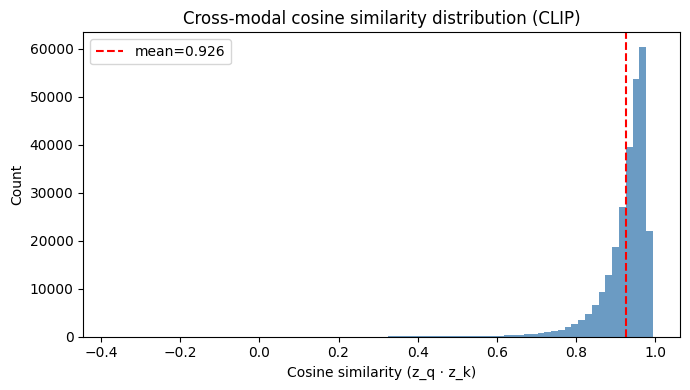

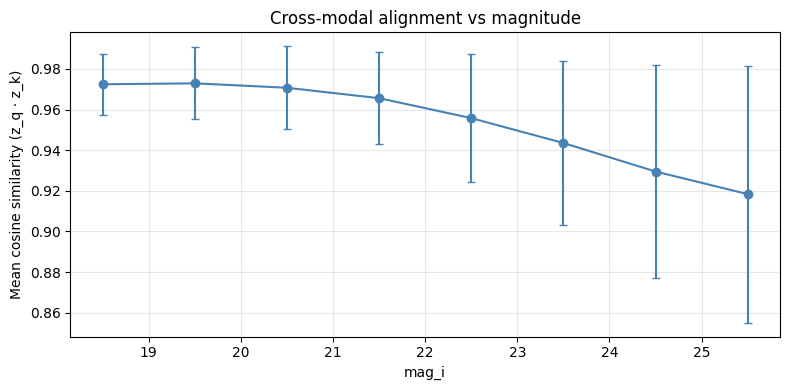

In [43]:
plot_cross_modal_cosine_sim(emb_data, det_df, out_dir=out_dir, savefig=True)

# Off-diagonal Similarity: Matched Pairs vs Random Pairs

In [5]:
def plot_matched_vs_random_similarity(emb_data, out_dir=None, n_subsample=2000, savefig=False):
    """
    Compare cosine similarity of matched (diagonal) pairs vs random
    (off-diagonal) pairs from z_q @ z_k.T.
 
    If contrastive training worked, matched-pair similarity should be
    substantially higher than random off-diagonal similarity. If everything
    collapses to the same point, both distributions would be near 1.0.
 
    Args:
        n_subsample: number of detections to subsample for the (N x N) matrix
                     (keep modest — memory is O(N^2))
    """
    if 'emb_k' not in emb_data and 'embeddings_k' not in emb_data:
        print("  [skip] No Roman embeddings — skipping matched vs random similarity.")
        return
 
    z_q = emb_data['emb_q'].float()
    z_k = emb_data['emb_k'].float() if 'emb_k' in emb_data else emb_data['embeddings_k'].float()
 
    # subsample to keep memory manageable
    n = min(len(z_q), n_subsample)
    np.random.seed(seed)
    idx = np.random.choice(len(z_q), n, replace=False)
    z_q_sub = z_q[idx]
    z_k_sub = z_k[idx]
 
    # full (N, N) similarity matrix
    sim_matrix = (z_q_sub @ z_k_sub.T).numpy()  # (N, N)
    # diagonal = matched pairs (same object, Rubin vs Roman)
    matched_sims = np.diag(sim_matrix)
    # off-diagonal = random unmatched pairs
    mask = ~np.eye(n, dtype=bool)
    random_sims  = sim_matrix[mask]
 
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(random_sims, bins=100, color='gray',      alpha=0.6, density=True,
            label=f'random pairs (n={len(random_sims):,}, mean={random_sims.mean():.3f})')
    ax.hist(matched_sims, bins=60, color='steelblue', alpha=0.8, density=True,
            label=f'matched pairs (n={n:,}, mean={matched_sims.mean():.3f})')
    ax.axvline(matched_sims.mean(), color='steelblue', linestyle='--', linewidth=1.5)
    ax.axvline(random_sims.mean(),  color='gray',      linestyle='--', linewidth=1.5)
    ax.set_xlabel('Cosine similarity (z_q · z_k)')
    ax.set_ylabel('Density')
    ax.set_title('Matched pairs vs random pairs: cross-modal similarity (CLIP)')
    ax.legend()
    fig.tight_layout()
    if savefig:
        fname = os.path.join(out_dir, 'cosine_sim_matched_vs_random.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}  "
              f"(matched mean={matched_sims.mean():.3f}, random mean={random_sims.mean():.3f})")

  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/cosine_sim_matched_vs_random.png  (matched mean=0.923, random mean=-0.002)


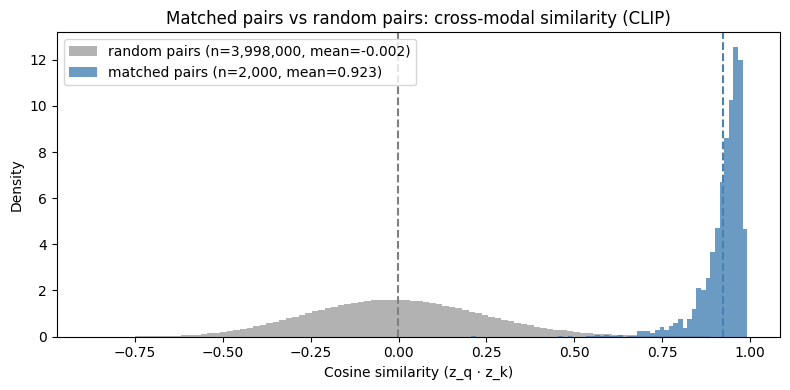

In [25]:
plot_matched_vs_random_similarity(emb_data, out_dir=out_dir, savefig=True)

  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs64_ep50/emb_plots/cosine_sim_matched_vs_random.png  (matched mean=0.945, random mean=0.001)


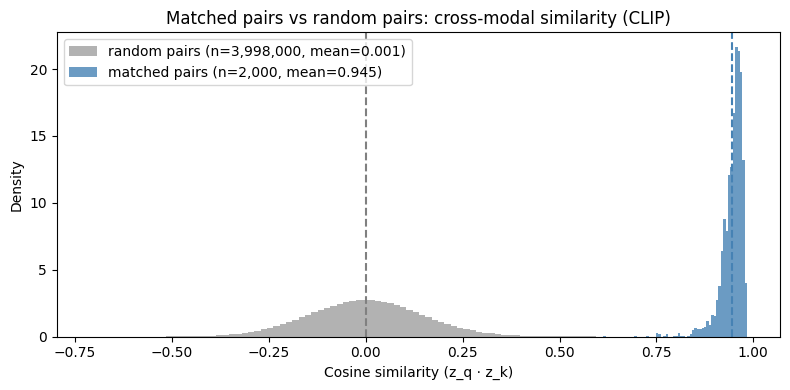

In [6]:
plot_matched_vs_random_similarity(emb_data, out_dir=out_dir, savefig=True)

Great, the matched distribution is tightly concentrated near 1.0 while the random distribution is centered near 0 meaning the model specifically aligned matched pairs rather than collapsing everything.

# Cross-modal sim by match type

In [18]:
fof_df['dd_is_part_of_blend'].value_counts()

dd_is_part_of_blend
False    453895
True      40200
Name: count, dtype: int64

In [8]:
def plot_cosine_sim_blend(emb_data, fof_df, out_dir=None, savefig=False):
    """
    Compare cross-modal cosine similarity across detection match types using
    the classified parquet saved by run_fof_classify.py

    A single match-type label is derived from the boolean flag columns
    in priority order: is_matched > is_shred > is_unrec_blend /
    is_resolved_blend / is_partial_deblend > is_spurious
    """
    if 'emb_k' not in emb_data and 'embeddings_k' not in emb_data:
        print("  [skip] No Roman embeddings — skipping blend cosine sim analysis.")
        return
    # keep only DD detection rows
    dets = fof_df[fof_df['catalog_key'] == 'dd_det'].copy()
    
    z_k = emb_data['emb_k'].float() if 'emb_k' in emb_data else emb_data['embeddings_k'].float()

    # derive a single match-type label from the boolean flag columns
    # Priority order: blend types > is_matched > is_shred > is_spurious
    # (Blend flags take precedence to separate matched objects that are part of blends)
    def _label(row):
        if row.get('dd_is_unrec_blend', False): return 'unrec_blend'
        if row.get('dd_is_resolved_blend', False): return 'res_blend'
        if row.get('dd_is_part_of_blend', False): return 'blend'
        if row.get('dd_is_matched', False): return 'matched'
        if row.get('dd_is_shred', False): return 'shred'
        if row.get('dd_is_spurious', False): return 'spurious'
        return 'other'
    
    dets['match_type'] = dets.apply(_label, axis=1)
    # align with embedding tensor via row_index
    cos_sim = F.cosine_similarity(emb_data['emb_q'].float(), z_k).numpy()
    dets['cos_sim'] = cos_sim[dets['row_index'].values]

    fig, ax = plt.subplots(figsize=(7, 4))
    for match_type, color in [
        ('matched',  'green'),
        ('blend',    'darkorange'),
        ('shred',    'lightgray'),
        ('spurious', 'gray'),
        ('unrec_blend', 'tomato'),
        ('res_blend', 'lightgreen'),
    ]:
        mask = dets['match_type'] == match_type
        if mask.sum() > 0:
            ax.hist(dets.loc[mask, 'cos_sim'], bins=50, alpha=0.6,
                    label=f'{match_type} (n={mask.sum():,})', color=color)
        else:
            print(f"  [warning] No detections of type '{match_type}' found in fof_df")
    ax.set_xlabel('Cosine similarity (z_q · z_k)')
    ax.set_yscale('log')
    ax.set_ylabel('Counts')
    ax.set_title('Cross-modal alignment by match type')
    ax.legend()
    fig.tight_layout()
    if savefig:
        fname = os.path.join(out_dir, 'cosine_sim_blend_vs_isolated.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}")

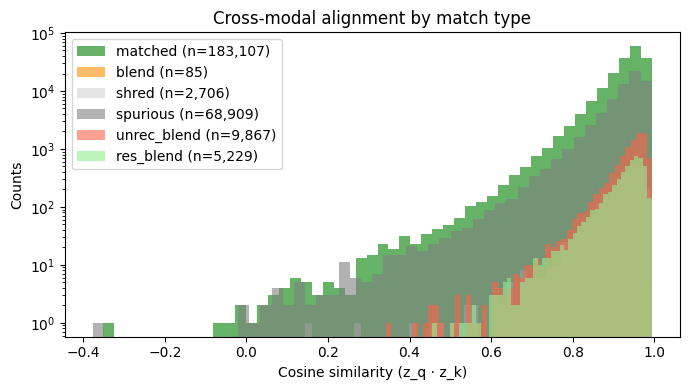

In [30]:
plot_cosine_sim_blend(emb_data, fof_df)

In [13]:
fof_df['catalog_key'].value_counts()

catalog_key
dd_det        254802
lsst_truth    224192
Name: count, dtype: int64

  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/cosine_sim_blend_vs_isolated.png


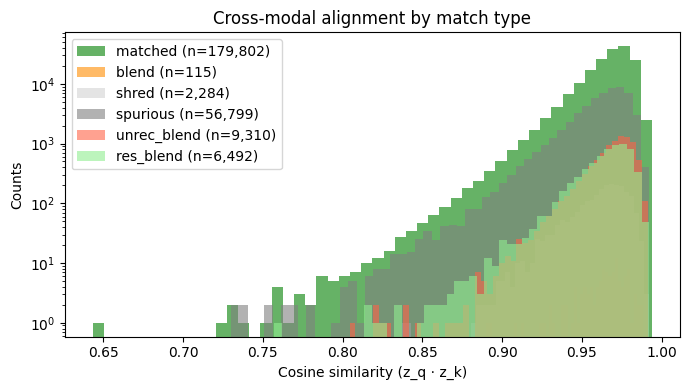

In [9]:
plot_cosine_sim_blend(emb_data, fof_df, out_dir=out_dir, savefig=True)

# Embedding Space Visualization

In [10]:
def get_matched_truth_col(dets, truths, prefix, col='mag_i'):
    """
    For each matched detection, look up the matched truth's column value.

    Parameters
    ----------
    dets : pd.DataFrame
        Detection rows.
    truths : pd.DataFrame
        Truth rows.
    prefix : str
        'dd' or 'lsst'.
    col : str
        Column name for value in truths. Default 'mag_i'.

    Returns
    -------
    pd.Series
        Aligned with dets index. NaN for unmatched detections.
    """
    # Build truth column lookup: row_index -> col
    truth_col_lookup = truths.set_index('row_index')[col]
    matched_id_col = f'{prefix}_matched_id'
    matched_mask = dets[f'{prefix}_is_matched']

    matched_truth_vals = dets.loc[matched_mask, matched_id_col].map(truth_col_lookup)
    result = pd.Series(np.nan, index=dets.index)
    result.loc[matched_mask] = matched_truth_vals.values
    return result

def _reduce(z, method, random_state=42, n_components=2):
    """Reduce z (N, d) to (N, n_components) using the requested method"""
    # - n_components is num of dim in output
    if method == 'umap':
        print(f"  Running UMAP on {len(z)} embeddings...")
        # - n_neighbors is number of neighbors for manifold approx (larger vals --> more global views of manifold while smaller vals --> more local views) default is 15
        # - metric is used to compute distances in high-d space
        # - min_dist is eff min dist between embedded points (default 0.1)
        #       smaller values will result in a more clustered/clumped embedding where nearby points on manifold are drawn closer together
        #       while larger values will result on a more even dispersal of points. Shld be set relative to spread value
        # - spread is eff scale of embedded points (default 1.0)
        #       with min_dist, this determines how clustered/clumped the embedded points are
        # - init is how to initialize the low-d embedding before optimization (default is 'spectral', but 'pca' is faster and often better for preserving global structure (Kobak and Linderman 2021))
        return UMAP(n_components=n_components, n_neighbors=30, metric='cosine', init='pca',
                    random_state=random_state).fit_transform(z)
    elif method == 'pacmap':
        print(f"  Running PaCMAP on {len(z)} embeddings...")
        # - n_neighbors is num of neighbors considered in k-Nearest neighbor graph and setting None enables auto-selection (10 for n < 10000)
        #   and n > 10000, it will be 10 + 15 * (log10(n) - 4)
        # - MN_ratio is ratio of num of mid-near pairs to num of neighbors (n_MN = MN_ratio * n_neighbors) default is 0.5
        # - FP_ratio is ratio of num of further pairs to num of neighbors (n_FP = FP_ratio * n_neighbors) default is 2.0
        # - distance is metric used for high-d space when constructing the neighbor graph (default is 'euclidean', but 'angular' probably better for CLIP embeddings)
        #   angular is cosine in PaCMAP
        # - apply_pca=False to avoid PaCMAP applying PCA by default since it does so for dims > 100
        #   we trained these 128 dims to be meaningful so we want to give PaCMAP the full representation to work with
        return PaCMAP(n_components=n_components, n_neighbors=None,
                      distance='angular', apply_pca=False,
                      random_state=random_state).fit_transform(z)
    elif method == 'tsne':
        print(f"  Running t-SNE on {len(z)} embeddings...")
        # - perplexity (default: 30) is related to number of nearest neighbors that's used in other manifold learning algos
        #       larger datasets usually require a larger perplexity (5 to 50)
        # - metric (default: 'euclidean') is used to compute distances in high-d space
        # - init is how to initialize the low-d embedding before optimization (default is 'pca')
        # - n_jobs is num of parallel jobs to run for neighbors search (default is None -> 1 unless in joblib.parallel backend, 
        #       but -1 uses all available cores)
        return TSNE(n_components=n_components, perplexity=30, metric='cosine',
                    random_state=random_state, n_jobs=-1).fit_transform(z)
    else:
        raise ValueError(f"Unknown method: {method}")

def _plot_embeddings(Z, df, method, out_dir, mag_col, savefig,
                     title_suffix='', fname_suffix='', size_col='size',
                     z_col='z', matched=False):
    """
    Generic embedding plotter

    Z: (N, D) array, D = 2 or 3
    matched=False -> 1x2 (class, magnitude)
    matched=True  -> 2x2 (class, magnitude, size, redshift)
    """
    D = Z.shape[1]
    if D not in (2, 3):
        raise ValueError(f"Z must have 2 or 3 dims, got {D}")

    proj_kw = {"projection": "3d"} if D == 3 else {}
    if matched:
        fig, axes = plt.subplots(2, 2, figsize=(14, 12), subplot_kw=proj_kw)
        axes = axes.ravel()
    else:
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw=proj_kw)
        axes = np.asarray(axes).ravel()

    tag = method.upper()

    # helper: scatter with 2D or 3D
    def _scatter(ax, coords, **kwargs):
        if D == 2:
            ax.scatter(coords[:, 0], coords[:, 1], **kwargs)
        else:
            ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], **kwargs)

    def _set_axes_labels(ax):
        ax.set_xlabel(f'{tag} dim 1')
        ax.set_ylabel(f'{tag} dim 2')
        if D == 3:
            ax.set_zlabel(f'{tag} dim 3')

    # color by class
    classes = df['class'].values  # 0 is galaxy 1 is star
    colors_cls = ['royalblue' if c == 0 else 'tomato' for c in classes]
    _scatter(axes[0], Z, c=colors_cls, s=4, alpha=0.5)
    axes[0].set_title(f'{tag} colored by class')
    _set_axes_labels(axes[0])
    axes[0].legend(handles=[
        Patch(color='royalblue', label='galaxy'),
        Patch(color='tomato', label='star'),
    ])

    # continuous-quantity helper
    def _plot_continuous(ax, value_col, label, cmap='viridis_r'):
        if value_col in df.columns:
            vals = df[value_col].values.astype(float)
            valid = np.isfinite(vals)
            if valid.any():
                vmin, vmax = np.nanpercentile(vals[valid], [5, 95])
                sc = _scatter(
                    ax, Z, c=vals, cmap=cmap,
                    s=4, alpha=0.5, vmin=vmin, vmax=vmax
                )
                plt.colorbar(sc, ax=ax, label=label)
                ax.set_title(f'{tag} colored by {label}')
            else:
                _scatter(ax, Z, color='lightgray', s=4, alpha=0.5)
                ax.set_title(f'{tag} ({label} all-NaN)')
        else:
            _scatter(ax, Z, color='lightgray', s=4, alpha=0.5)
            ax.set_title(f'{tag} (no {label} column available)')

        _set_axes_labels(ax)

    # first row right: magnitude
    _plot_continuous(axes[1], mag_col, mag_col, cmap='viridis_r')

    # second row only for matched truth plots
    if matched:
        _plot_continuous(axes[2], size_col, size_col, cmap='magma')
        _plot_continuous(axes[3], z_col, z_col, cmap='coolwarm')

    # title + save
    dim_tag = f'{D}D, ' if D == 3 else ''
    suptitle = f'CLIP model: z_q embedding space via {tag} ({dim_tag}n={len(Z):,})'
    if title_suffix:
        suptitle += f' ({title_suffix})'
    fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if savefig:
        if not out_dir:
            raise ValueError("out_dir must be provided when savefig=True")
        fname = os.path.join(out_dir, f'{method}_clip{fname_suffix}_{D}d.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}")

def run_plot(emb_data, det_df, out_dir=None, reducer=['pacmap', 'umap'], n_components=2,
             n_subsample=3000, mag_col='mag_i', savefig=False, fof_df=None):
    """
    Visualise z_q/k embeddings in 2D/3D using UMAP, PaCMAP, and/or t-SNE

    Args:
        reducer: list/tuple of methods, e.g. ['pacmap', 'umap']
    """
    if not isinstance(reducer, (list, tuple)) or len(reducer) == 0:
        raise ValueError("reducer must be a non-empty list/tuple of methods.")

    allowed_methods = {'umap', 'pacmap', 'tsne'}
    methods = []
    for method in reducer:
        if method not in allowed_methods:
            raise ValueError(f"Unknown method: {method}. Choose from {sorted(allowed_methods)}")
        methods.append(method)

    z_q = emb_data['emb_q'].float()
    n = min(len(z_q), n_subsample)
    np.random.seed(seed)
    idx = np.random.choice(len(z_q), n, replace=False)
    z = z_q[idx].numpy()
    df = det_df.iloc[idx].reset_index(drop=True)

    for method in methods:
        z_low = _reduce(z, method, random_state=seed, n_components=n_components)
        _plot_embeddings(z_low, df, method, out_dir, mag_col, savefig)
            
    if fof_df is None:
        print("  [info] No fof_df provided, skipping matched-only visualisation.")
        return

    truths = fof_df[fof_df['catalog_key'] == 'lsst_truth']
    dets = fof_df[fof_df['catalog_key'] == 'dd_det'].copy()
    dets['truth_mag_i'] = get_matched_truth_col(dets, truths, prefix='dd', col=mag_col)
    dets['truth_size'] = get_matched_truth_col(dets, truths, prefix='dd', col='size')
    dets['truth_z'] = get_matched_truth_col(dets, truths, prefix='dd', col='z')

    matched = dets[dets['dd_is_matched'] == True]
    if len(matched) == 0:
        print("  [skip] No matched detections in fof_df ")
        return

    matched_idx = matched['row_index'].values  # iloc pos in det_df/emb tensor
    n_matched = min(len(matched_idx), n_subsample)
    
    np.random.seed(seed)
    chosen = np.random.choice(len(matched_idx), n_matched, replace=False)
    matched_idx_sub = matched_idx[chosen]
    matched_df_sub = matched.iloc[chosen].reset_index(drop=True)

    # plot_df holds truth-based targets for matched subset coloring.
    plot_df = pd.DataFrame(
        {
            'class': matched_df_sub['class'].values,
            mag_col: matched_df_sub['truth_mag_i'].values,
            'size': matched_df_sub['truth_size'].values,
            'z': matched_df_sub['truth_z'].values,
        },
        index=range(n_matched),
    )

    z_matched = z_q[matched_idx_sub].numpy()
    print(f"  Running matched-only visualisation ({n_matched:,} detections)...")
    for method in methods:
        z_low = _reduce(z_matched, method, random_state=seed, n_components=n_components)
        _plot_embeddings(z_low, df, method, out_dir, mag_col, savefig, 
                         title_suffix='Matched', fname_suffix='_matched', size_col='size', 
                         z_col='z', matched=True)

Note: `n_components != 2` have not been thoroughly tested.
Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running PaCMAP on 3000 embeddings...


RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

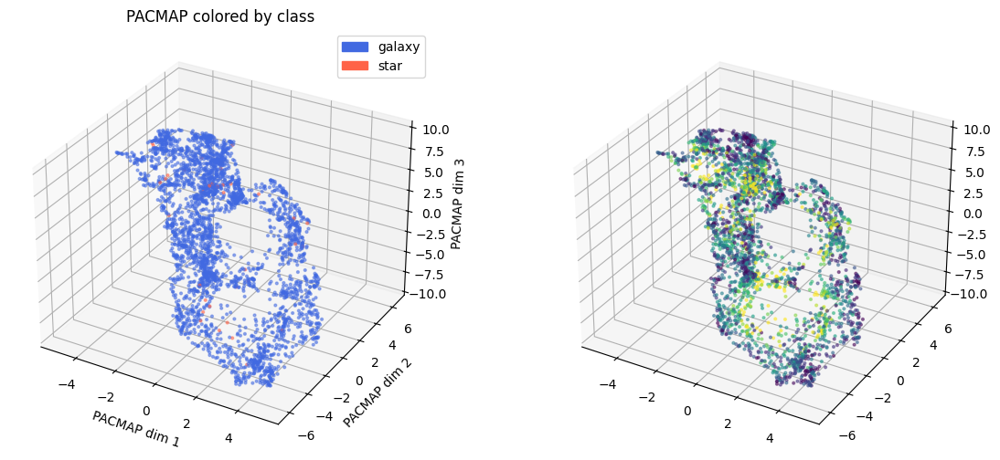

In [11]:
run_plot(emb_data, det_df, n_components=3)

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running PaCMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/pacmap_clip.png
  Running UMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/umap_clip.png


Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running matched-only visualisation (50,000 detections)...
  Running PaCMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/pacmap_clip_matched.png
  Running UMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/umap_clip_matched.png


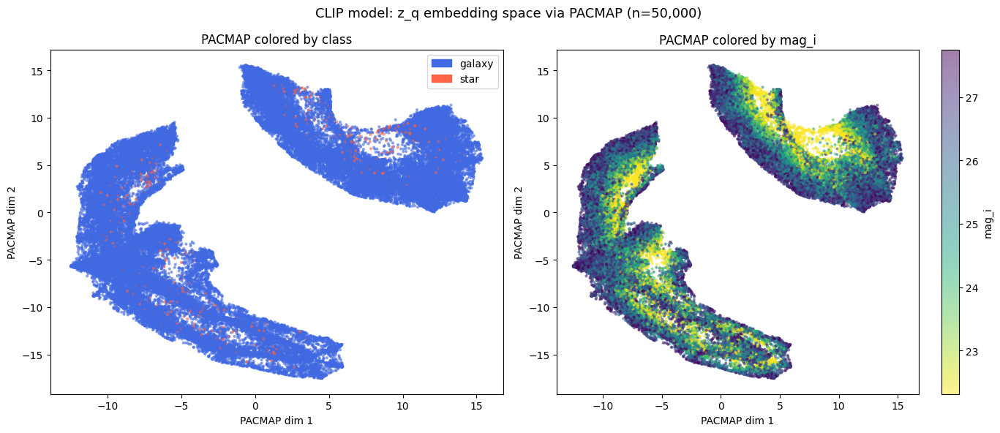

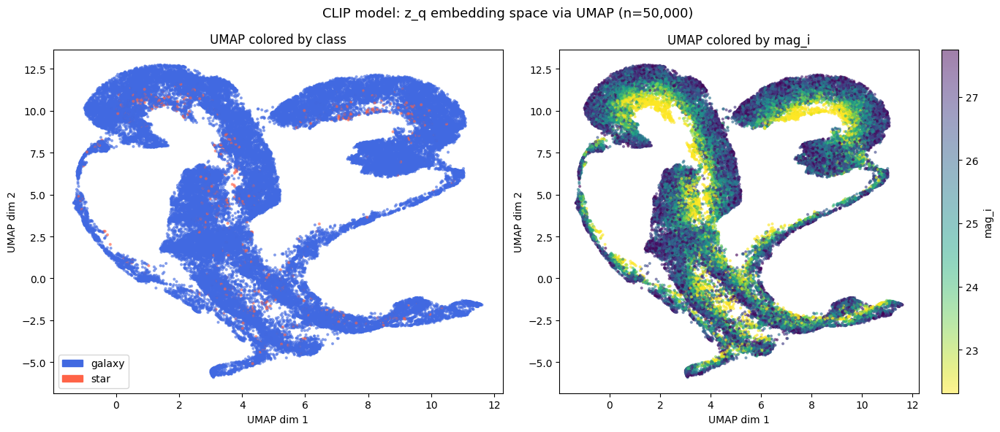

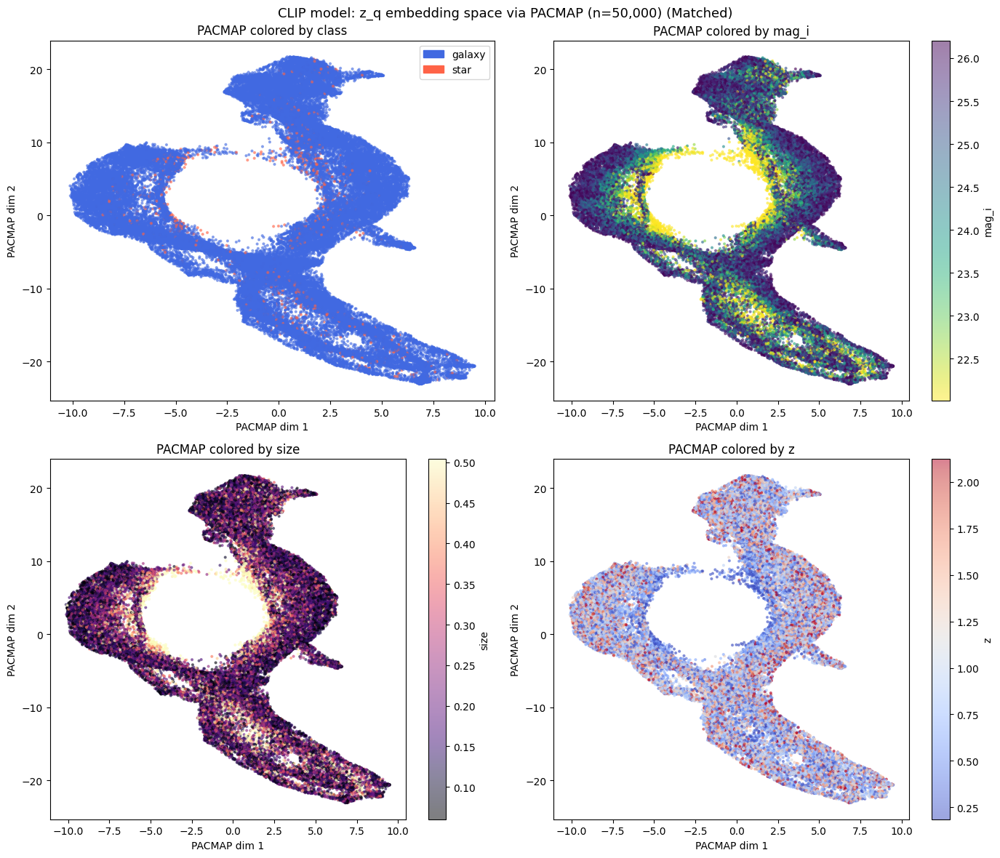

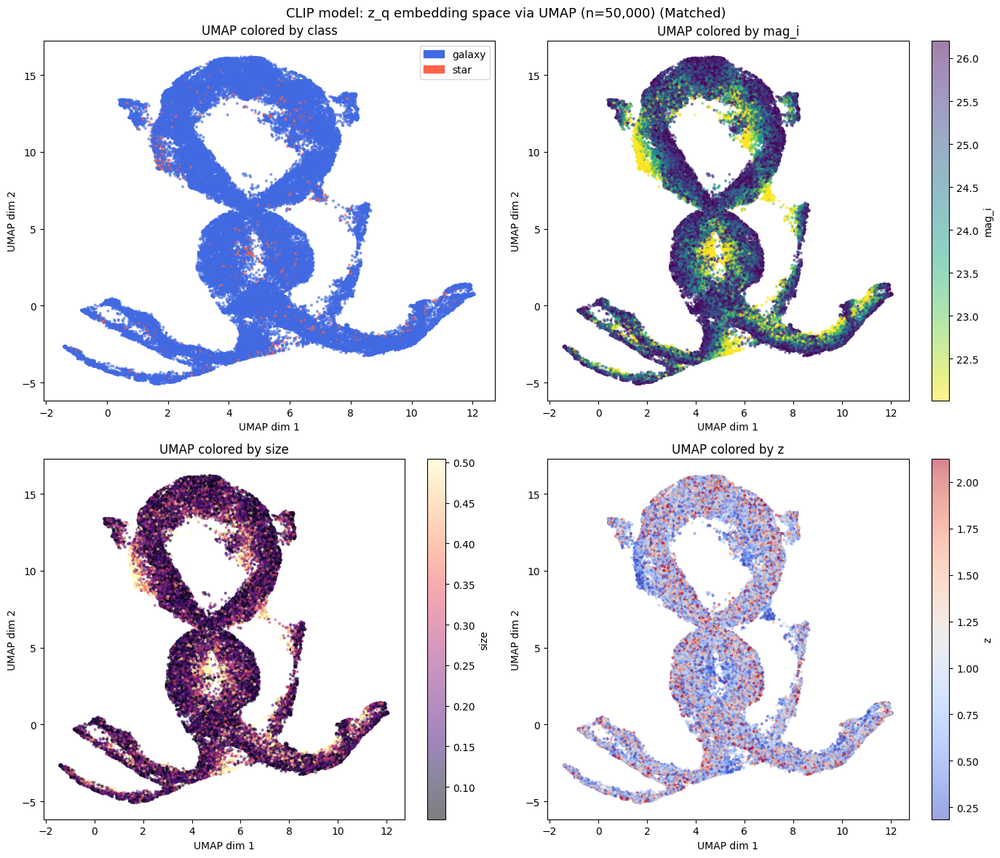

In [ ]:
# PaCAMP
# 11.5s for 10k subsample
# 51s for 50k subsample 
# UMap
# 15s for 10k
# 12.9s for 50k
# t-SNE
# 7m13s for 50k subsample
run_plot(emb_data, det_df, out_dir=out_dir, n_subsample=50000, fof_df=fof_df, savefig=True)

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running PaCMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/pacmap_clip.png
  Running UMAP on 50000 embeddings...


/u/yse2/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/umap_clip.png


Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running matched-only visualisation (50,000 detections)...
  Running PaCMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/pacmap_clip_matched.png
  Running UMAP on 50000 embeddings...


/u/yse2/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/umap_clip_matched.png


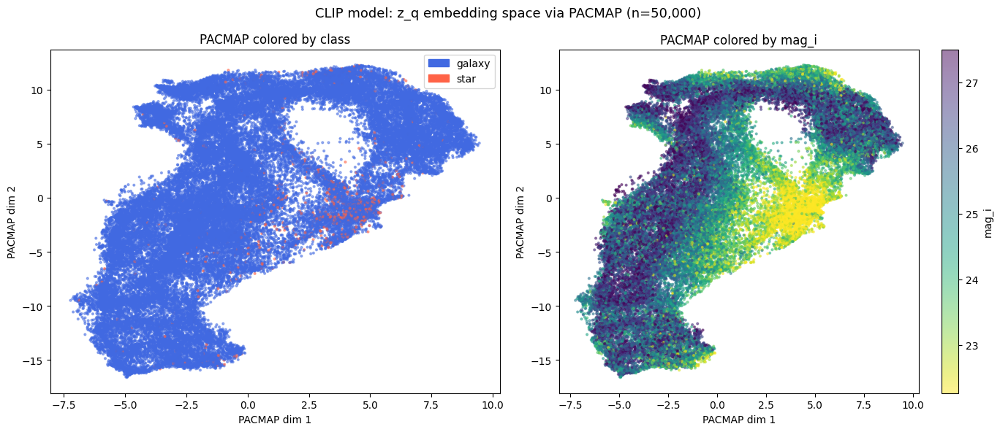

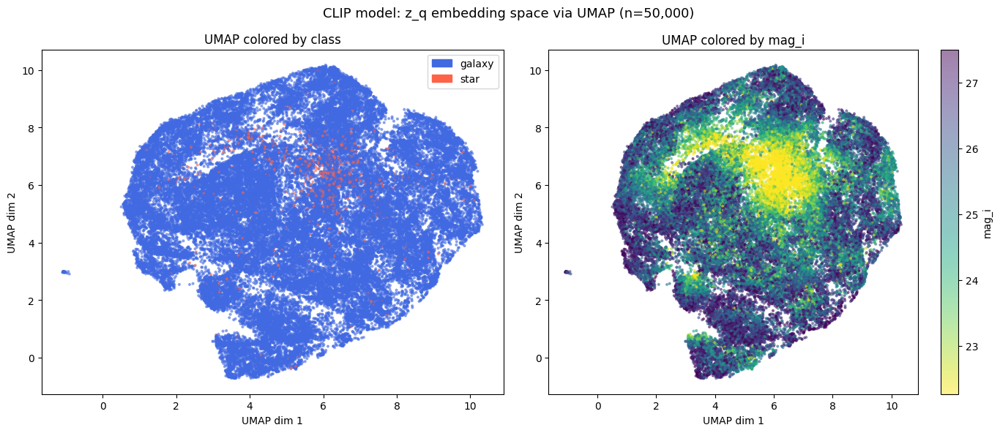

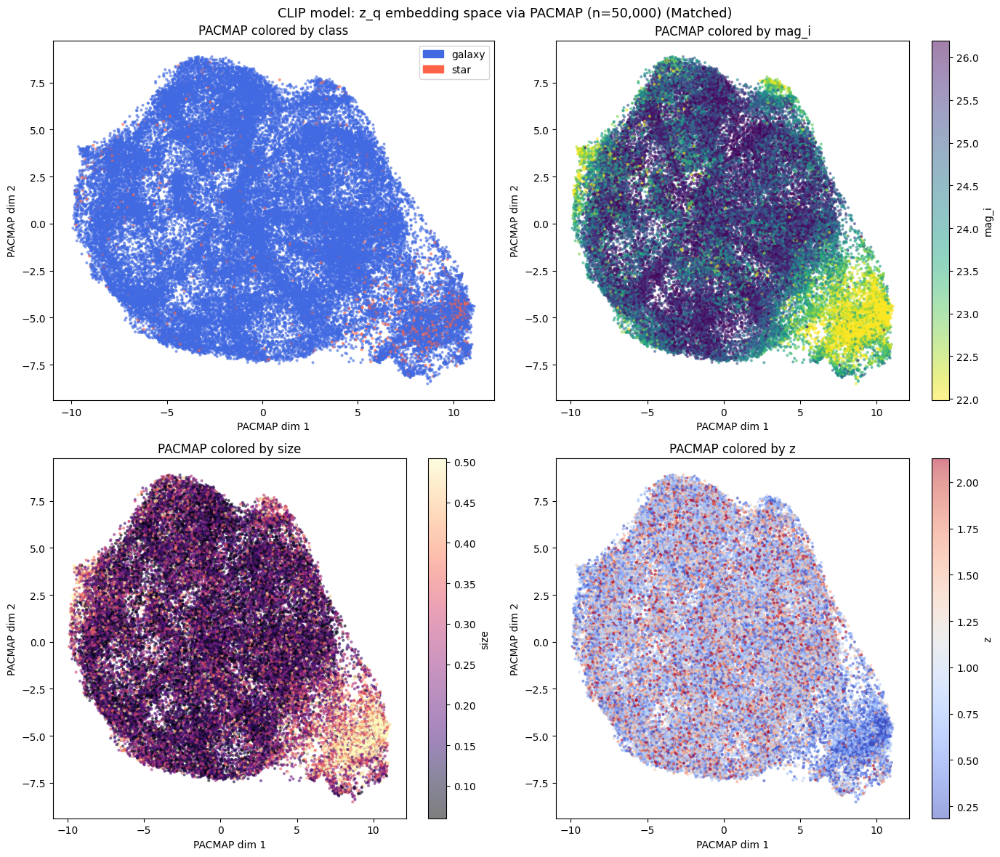

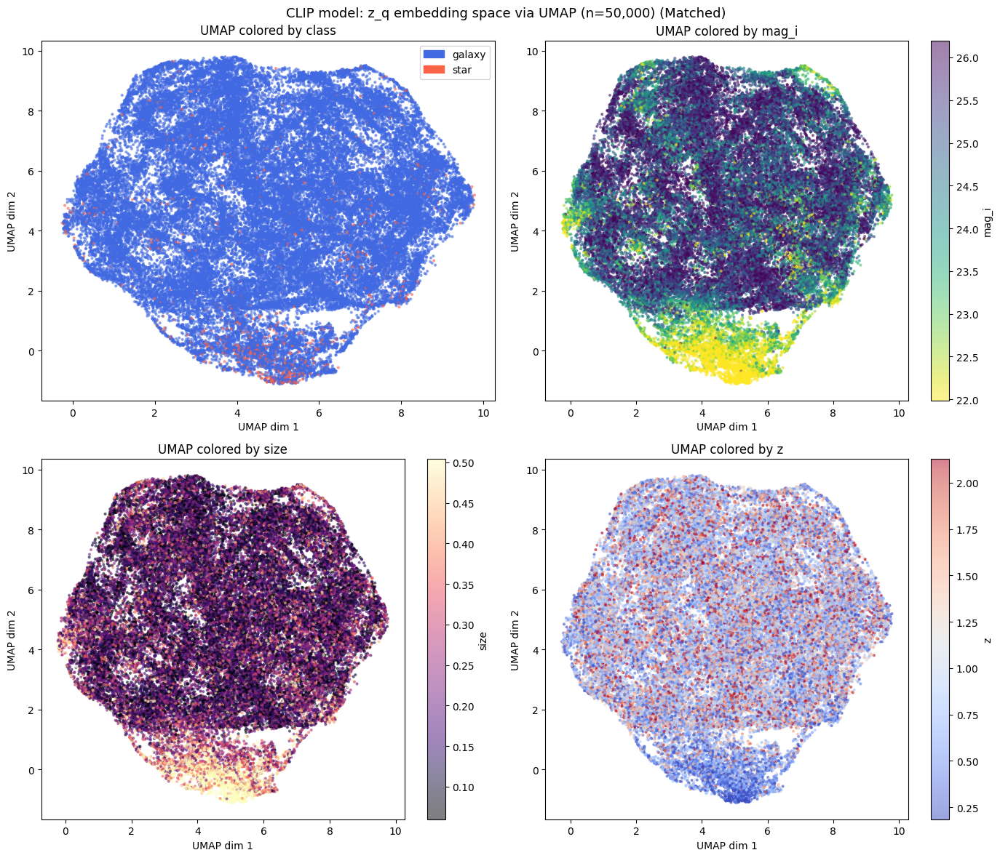

In [ ]:
# PaCAMP
# 11.5s for 10k subsample
# 51s for 50k subsample 
# UMap
# 15s for 10k
# 12.9s for 50k
# t-SNE
# 7m13s for 50k subsample
run_plot(emb_data, det_df, out_dir=out_dir, n_subsample=50000, fof_df=fof_df, savefig=True)

  Running t-SNE on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/tsne_clip.png


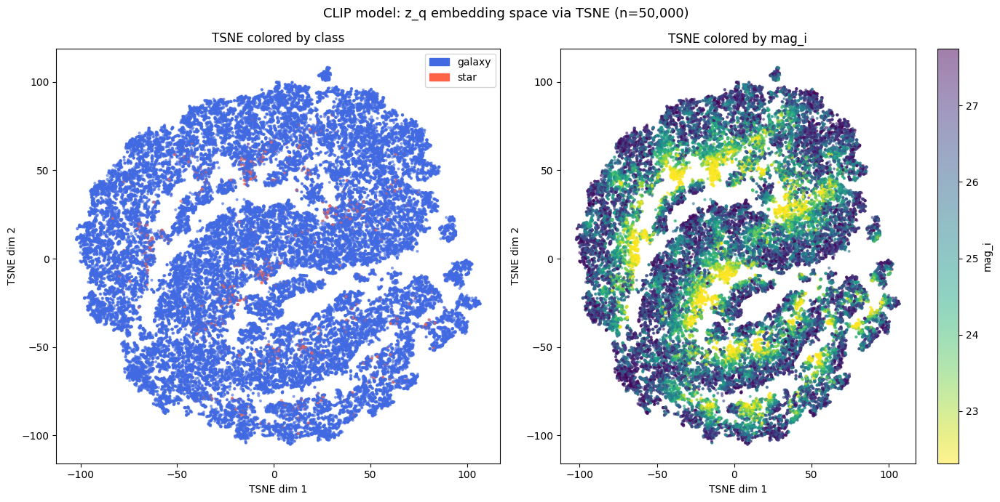

In [ ]:
# 7m13s for 50k subsample
run_plot(emb_data, det_df, n_subsample=50000, out_dir=out_dir, reducer=['tsne'], savefig=True)

# Joint 2D Projection of z_q and z_k

In [ ]:
def plot_joint_embedding(emb_data, out_dir=None, reducer='pacmap', include_lines=True,
                         n_subsample=1000, savefig=False, fname_suffix=''):
    """
    Concatenate z_q and z_k, run a single reducer on the combined set, then
    plot Rubin (z_q) and Roman (z_k) points with lines connecting matched pairs.
 
    Running the reducer on concatenated embeddings allows us to
    compare their positions in 2D because running two independent reductions gives
    coords with no shared reference frame
 
    If contrastive training aligned the two modalities, matched pairs should
    land close together in the 2D projection
 
    Args:
        reducer:     which method to use — 'pacmap' or 'umap'
        n_subsample: number of matched pairs to visualise (lines get cluttered
                     above ~1000)
    """
    if 'emb_k' not in emb_data and 'embeddings_k' not in emb_data:
        print("  [skip] No Roman embeddings — skipping joint embedding plot.")
        return
 
    z_q = emb_data['emb_q'].float()
    z_k = emb_data['emb_k'].float() if 'emb_k' in emb_data else emb_data['embeddings_k'].float()
 
    n = min(len(z_q), n_subsample)
    np.random.seed(seed)
    idx = np.random.choice(len(z_q), n, replace=False)
    z_q_sub = z_q[idx].numpy()   # (n, 128)
    z_k_sub = z_k[idx].numpy()   # (n, 128)
 
    # stack: first n rows = Rubin, next n rows = Roman
    z_combined = np.concatenate([z_q_sub, z_k_sub], axis=0)  # (2n, 128)
 
    print(f"  Running joint {reducer.upper()} on {2*n} embeddings ({n} pairs)...")
    z_2d = _reduce(z_combined, reducer)
 
    z_2d_q = z_2d[:n]   # Rubin points
    z_2d_k = z_2d[n:]   # Roman points
 
    fig, ax = plt.subplots(figsize=(8, 8))
    # draw lines between matched pairs first (behind the scatter points)
    if include_lines:
        for i in range(n):
            ax.plot([z_2d_q[i, 0], z_2d_k[i, 0]],
                    [z_2d_q[i, 1], z_2d_k[i, 1]],
                    color='gray', alpha=0.25, linewidth=0.5, zorder=1)
 
    ax.scatter(z_2d_q[:, 0], z_2d_q[:, 1], c='steelblue', s=5, alpha=0.5,
               label='Rubin (z_q)', zorder=2)
    ax.scatter(z_2d_k[:, 0], z_2d_k[:, 1], c='tomato', marker='x', s=5, alpha=0.3,
               label='Roman (z_k)', zorder=2)
    if include_lines:
        ax.set_title(
            f'Joint {reducer.upper()} of z_q and z_k (n={n:,} pairs)\n'
            'Lines connect matched pairs — short lines = good cross-modal alignment'
        )
    else:
        ax.set_title(f'Joint {reducer.upper()} of z_q and z_k (n={n:,} pairs)')
    ax.set_xlabel(f'{reducer.upper()} dim 1')
    ax.set_ylabel(f'{reducer.upper()} dim 2')
    ax.legend(markerscale=2)
    fig.tight_layout()
    if savefig:
        fname = os.path.join(out_dir, f'joint_embedding_{reducer}_{fname_suffix}.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}")

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running joint PACMAP on 10000 embeddings (5000 pairs)...
  Running PaCMAP on 10000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/joint_embedding_pacmap_5kp.png


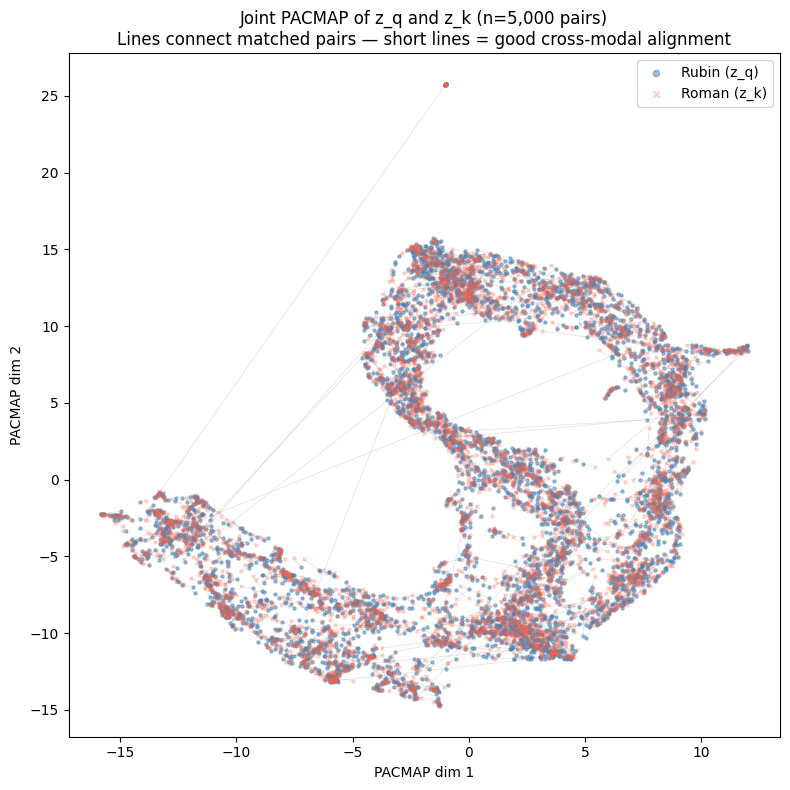

In [ ]:
plot_joint_embedding(emb_data, n_subsample=5000, out_dir=out_dir, savefig=True, fname_suffix='5kp')

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running joint PACMAP on 10000 embeddings (5000 pairs)...
  Running PaCMAP on 10000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/joint_embedding_pacmap_5kp.png


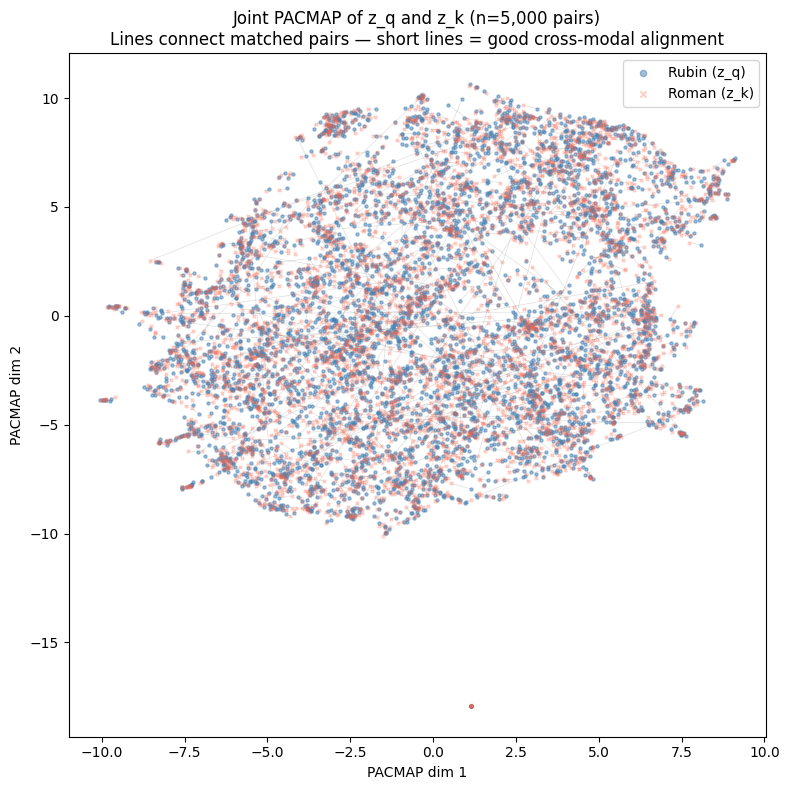

In [17]:
plot_joint_embedding(emb_data, n_subsample=5000, out_dir=out_dir, savefig=True, fname_suffix='5kp')

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running joint PACMAP on 50000 embeddings (25000 pairs)...
  Running PaCMAP on 50000 embeddings...


/tmp/ipykernel_661538/1603433762.py:63: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(fname, dpi=150)


  Saved /u/yse2/lsst_runs/clip5_30k_4h200_bs192_ep15/emb_plots/joint_embedding_pacmap_25kp.png


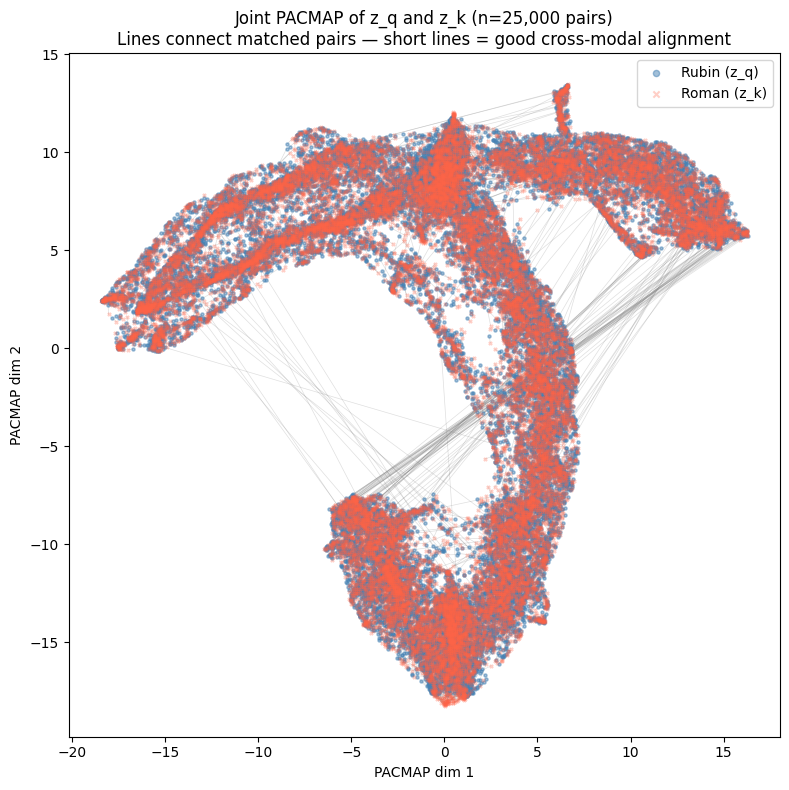

In [7]:
plot_joint_embedding(emb_data, n_subsample=25000, out_dir=out_dir, savefig=True, fname_suffix='25kp')

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running joint PACMAP on 50000 embeddings (25000 pairs)...
  Running PaCMAP on 50000 embeddings...


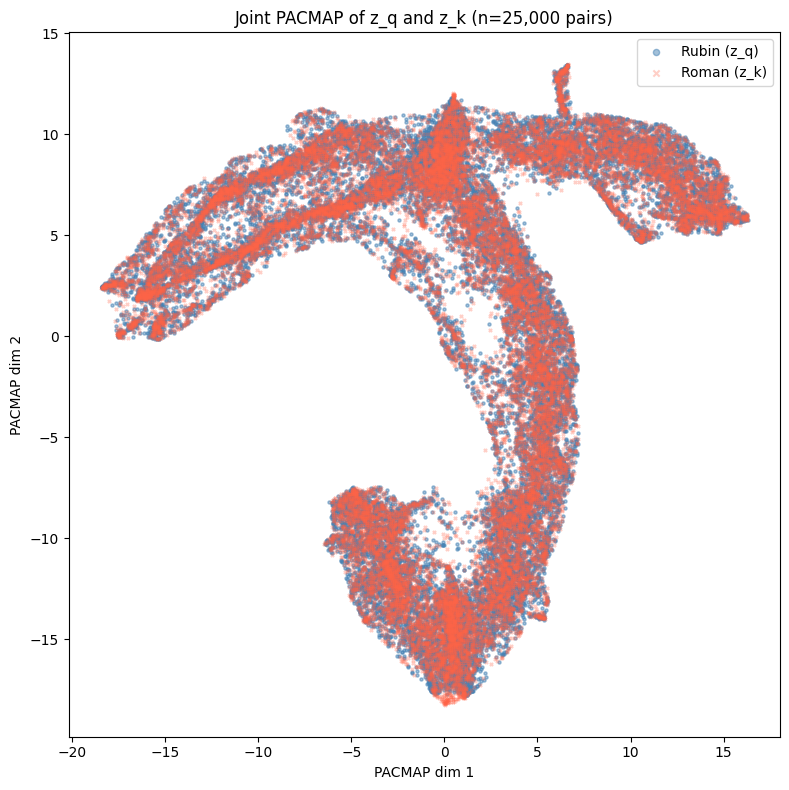

In [7]:
plot_joint_embedding(emb_data, n_subsample=25000, include_lines=False)

Running NN Backend on high-dimensional data. Nearest-neighbor search may be slow!


  Running joint PACMAP on 50000 embeddings (25000 pairs)...
  Running PaCMAP on 50000 embeddings...
  Saved /u/yse2/lsst_runs/clip5_flatten_30k_4h200_bs64_ep15/emb_plots/joint_embedding_pacmap_25kp.png


/projects/bdsp/miniconda3/envs/ddbtknv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


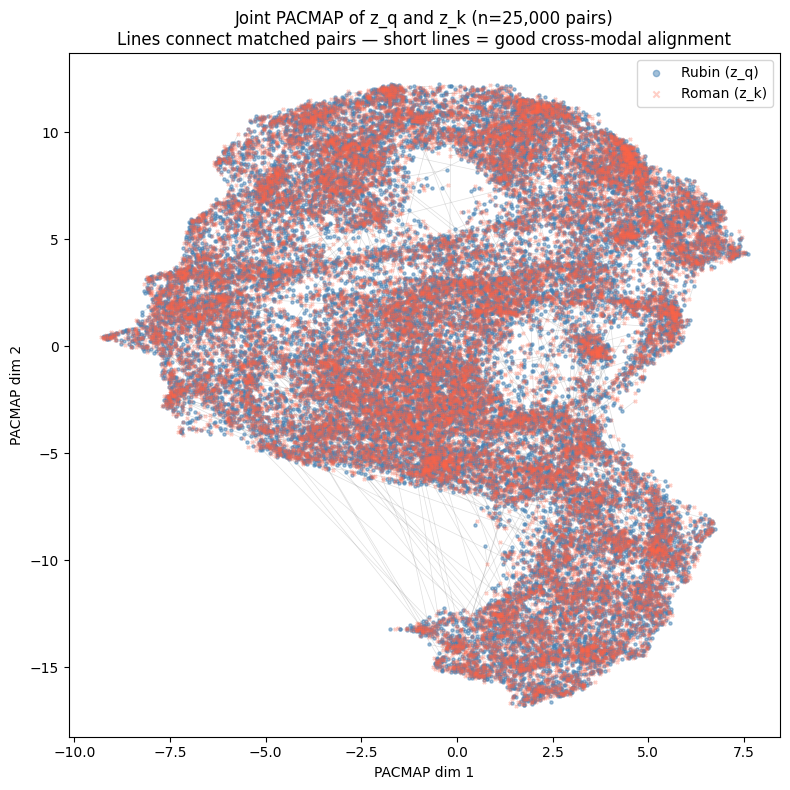

In [18]:
plot_joint_embedding(emb_data, n_subsample=25000, out_dir=out_dir, savefig=True, fname_suffix='25kp')

If our model was failing, we'd see a "blue island" of Rubin points and a completely separate "red island" of Roman points. That would mean the model just learned to separate images by which telescope took them. Instead, in the 25k plot, the blue and red points are heavily interleaved. They share the exact same macro-structure. This proves our encoders have learned a modality-agnostic embedding space. The model is organizing these points based on the physical features of the objects (like magnitude and size), not the instrument that captured them.

In [37]:
test_df.index

RangeIndex(start=0, stop=8571, step=1)

In [135]:
from astropy.visualization import make_lupton_rgb
from astropy.wcs import WCS
from detectron2.structures import Boxes, Instances
import pycocotools.mask as mask_util
from deepdisc.astrodet.visualizer import Visualizer, ColorMode

def _rubin_bbox_to_roman(bbox, wcs_rubin, wcs_roman):
    """
    Convert a Rubin bbox [x1, y1, x2, y2] to Roman pixel coordinates using
    WCS reprojection (Rubin pixel -> RA/Dec -> Roman pixel).
 
    Parameters
    ----------
    bbox : array-like, shape (4,)
        [x1, y1, x2, y2] in Rubin pixel coordinates.
    wcs_rubin : astropy.wcs.WCS
    wcs_roman : astropy.wcs.WCS
 
    Returns
    -------
    np.ndarray, shape (4,) — [x1, y1, x2, y2] in Roman pixel coordinates
    """
    corners = np.array([
        [bbox[0], bbox[1]],
        [bbox[2], bbox[3]],
    ], dtype=np.float64)
    ra, dec = wcs_rubin.wcs_pix2world(corners[:, 0], corners[:, 1], 0)
    x_rom, y_rom = wcs_roman.wcs_world2pix(ra, dec, 0)
    x1, x2 = sorted([x_rom[0], x_rom[1]])
    y1, y2 = sorted([y_rom[0], y_rom[1]])
    return np.array([x1, y1, x2, y2])
 
def _crop(img, x1, y1, x2, y2, pad=10):
    """Crop image (H, W, C) at [x1,y1,x2,y2] with optional padding, clamped to image bounds."""
    H, W = img.shape[0], img.shape[1]  # (H, W, C)
    x1 = max(0, int(x1) - pad)
    y1 = max(0, int(y1) - pad)
    x2 = min(W, int(x2) + pad)
    y2 = min(H, int(y2) + pad)
    return img[y1:y2, x1:x2]

def _make_rgb(raw, roman=False):
    # Bands: 3=i, 2=r, 1=g
    if not roman:
        i, r, g = raw[3, :, :], raw[2, :, :], raw[1, :, :]
    # HJY
    else:
        i, r, g = raw[2, :, :], raw[1, :, :], raw[0, :, :]
    pmin = np.percentile([i, r, g], 1)
    pmax = np.percentile([i, r, g], 99.5)
    stretch = pmax - pmin # + 1e-6
    return make_lupton_rgb(i, r, g, minimum=pmin, stretch=stretch, Q=10) 

def plot_alignment_failures(emb_data, det_df, test_df, out_dir,
                             metadata, top_pct=0.01, n_show=16,
                             savefig=False):
    if 'emb_k' not in emb_data and 'embeddings_k' not in emb_data:
        print("  [skip] No Roman embeddings — skipping alignment failure crops.")
        return

    z_q = emb_data['emb_q'].float()
    z_k = emb_data['emb_k'].float() if 'emb_k' in emb_data else emb_data['embeddings_k'].float()
    cos_sim  = F.cosine_similarity(z_q, z_k).numpy()
    cos_dist = 1.0 - cos_sim
    n_failures = max(1, int(len(cos_dist) * top_pct))
    failure_idx = np.argsort(cos_dist)[-n_failures:][::-1]
    show_idx = failure_idx[:n_show]

    test_df_indexed = test_df.set_index('file_name')
    n_cols = 4
    n_rows = int(np.ceil(len(show_idx) / n_cols)) * 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = axes.flatten()

    pad = 10
    plotted = 0
    for rank, det_i in enumerate(show_idx):
        fn   = emb_data['file_name'][det_i]
        row  = test_df_indexed.loc[fn]
        wcs_rubin = WCS(row['wcs'])
        wcs_roman = WCS(row['wcs_roman'])

        det   = det_df.iloc[det_i]
        bbox  = det['bbox']          # [x1, y1, x2, y2]
        dist  = cos_dist[det_i]

        # --- build a single-instance Instances object for the Visualizer ---
        h, w  = int(bbox[3]) - int(bbox[1]) + 2*pad, int(bbox[2]) - int(bbox[0]) + 2*pad
        inst  = Instances((h, w))   # image_size doesn't matter for draw_instance_predictions
        inst.pred_boxes   = Boxes(torch.tensor([[bbox[0], bbox[1], bbox[2], bbox[3]]]))
        inst.scores       = torch.tensor([det['score']])
        inst.pred_classes = torch.tensor([int(det['class'])])
        # decode RLE mask and store as BitmapMasks-compatible bool tensor
        mask = mask_util.decode(det['rle_masks']).astype(bool)  # (H_full, W_full)
        inst.pred_masks   = torch.from_numpy(mask[None])        # (1, H_full, W_full)

        # --- Rubin: Visualizer on full image, then crop ---
        rubin_img  = np.load(fn)
        rgb_rubin  = _make_rgb(rubin_img, roman=False)          # (H, W, 3) float [0,1] uint8
        vis        = Visualizer(rgb_rubin.copy(), metadata=metadata,
                                instance_mode=ColorMode.SEGMENTATION, 
                                enable_color_jitter=False)
        vis_out    = vis.draw_instance_predictions(inst, lf=False, boxf=True, draw_masks=True)
        vis_img    = vis_out.get_image()                        # (H, W, 3) uint8
        rubin_crop = _crop(vis_img, bbox[0], bbox[1], bbox[2], bbox[3])

        # --- Roman: plain crop + reprojected bbox rect ---
        roman_fn   = fn.replace('lsst_data', 'roman_data')
        roman_img  = np.load(roman_fn)
        rgb_roman  = _make_rgb(roman_img, roman=True)
        roman_bbox = _rubin_bbox_to_roman(bbox, wcs_rubin, wcs_roman)

        # skip if Roman bbox is degenerate
        H_rom, W_rom = rgb_roman.shape[:2]
        if (roman_bbox[2] <= 0 or roman_bbox[0] >= W_rom or
            roman_bbox[3] <= 0 or roman_bbox[1] >= H_rom):
            print(f"  [skip] Roman bbox out of bounds for {fn}")
            continue

        roman_crop = _crop(rgb_roman, roman_bbox[0], roman_bbox[1],
                           roman_bbox[2], roman_bbox[3])
        if roman_crop.size == 0:
            print(f"  [skip] Empty Roman crop for {fn}")
            continue

        ax_r = axes[plotted * 2]
        ax_k = axes[plotted * 2 + 1]

        ax_r.imshow(rubin_crop, origin='lower')
        ax_r.set_title(f'#{rank+1} Rubin\ndist={dist:.3f}', fontsize=8)
        ax_r.axis('off')

        ax_k.imshow(roman_crop, origin='lower')
        # draw reprojected bbox on Roman crop, offset to crop origin
        rom_crop_x1 = max(0, int(roman_bbox[0]) - pad)
        rom_crop_y1 = max(0, int(roman_bbox[1]) - pad)
        rom_box_x   = int(roman_bbox[0]) - rom_crop_x1
        rom_box_y   = int(roman_bbox[1]) - rom_crop_y1
        rom_box_w   = int(roman_bbox[2]) - int(roman_bbox[0])
        rom_box_h   = int(roman_bbox[3]) - int(roman_bbox[1])
        ax_k.add_patch(plt.Rectangle((rom_box_x, rom_box_y), rom_box_w, rom_box_h,
                       edgecolor='lime', facecolor='none', linewidth=1.5))
        for ann in row['annotations']:
            cx, cy = ann['keypoints'][0], ann['keypoints'][1]
            # check if this object falls within the rubin bbox
            if not (bbox[0] <= cx <= bbox[2] and bbox[1] <= cy <= bbox[3]):
                continue
            # reproject to Roman pixel space
            ra_obj, dec_obj = wcs_rubin.wcs_pix2world(cx, cy, 0)
            x_rom_obj, y_rom_obj = wcs_roman.wcs_world2pix(ra_obj, dec_obj, 0)
            # offset to crop origin
            x_rom_rel = x_rom_obj - rom_crop_x1
            y_rom_rel = y_rom_obj - rom_crop_y1
            ax_k.scatter(x_rom_rel, y_rom_rel, c='red', s=100, marker='+',
                        linewidths=1.5, zorder=3)
        ax_k.set_title(f'#{rank+1} Roman\ndist={dist:.3f}', fontsize=8)
        ax_k.axis('off')

        plotted += 1

    for ax in axes[plotted * 2:]:
        ax.axis('off')

    fig.suptitle(
        f'Top {int(top_pct*100)}% alignment failures (worst {n_show} shown)\n'
        'Left=Rubin (Visualizer), Right=Roman (reprojected bbox)',
        fontsize=10
    )
    fig.tight_layout()
    if savefig:
        fname = os.path.join(out_dir, 'alignment_failures.png')
        fig.savefig(fname, dpi=150)
        print(f"  Saved {fname}  (worst dist={cos_dist[show_idx[0]]:.3f})")

In [99]:
from deepdisc.data_format.register_data import register_data_set
from detectron2.data import DatasetCatalog, MetadataCatalog
from omegaconf import OmegaConf

test = "test"
try:
    DatasetCatalog.remove(test)
    MetadataCatalog.remove(test)
except:
    pass
custom_colors = [
    (0, 255, 0),    # green for galaxies
    (0, 0, 255),    # blue for stars
]
metadata = OmegaConf.create() 
metadata.classes = ["galaxy", "star"]
astrotest_metadata = register_data_set(
    test, '/u/yse2/lsst_data/annotations_lvl5/test_8k_keypoints_wcs.json', thing_classes=metadata.classes, thing_colors=custom_colors
)

Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors
Setting colors


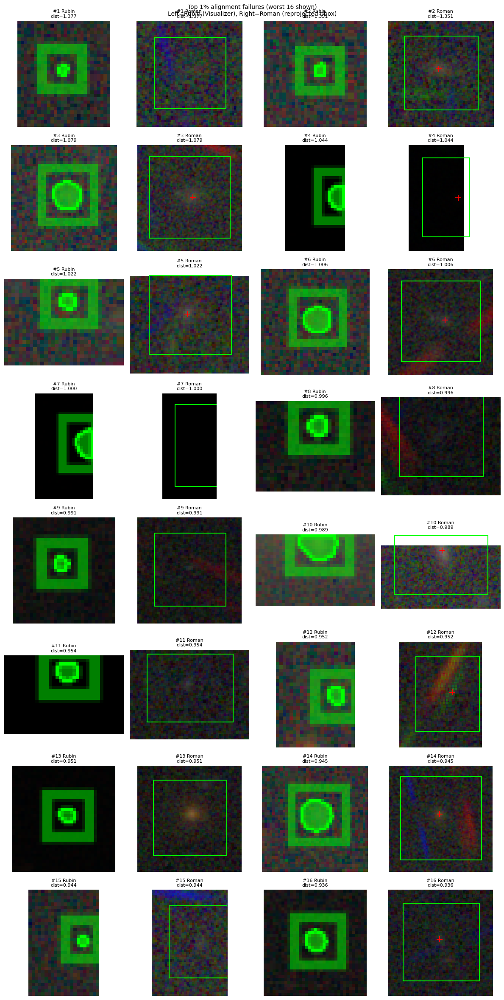

In [136]:
plot_alignment_failures(emb_data, det_df, test_df, out_dir, metadata=astrotest_metadata, top_pct=0.01)